# Cross-corpus analysis -- harness, model, and license-family comparisons

Compares the two analysis-ready Terminal-Bench corpora under
`data/curated/terminal_bench_2_*/trajectories.jsonl`. Terminal-Bench 2.0
contains only usable trajectories with known outcomes. Terminal-Bench 2.1
retains all usable trajectories and uses `resolved_available` when outcome
metadata is missing.

The main questions are whether trajectory structure varies by
harness, model, outcome, benchmark version, difficulty, and effort proxies
such as tokens, steps, and duration.

All cells stream trajectory records and retain only one lightweight summary
row per trajectory; step contents are not kept in memory.

In [39]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "zest").exists():
    PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from zest.paths import CURATED_TERMINAL_BENCH, DATA_DIR
from zest.schema import read_jsonl

BLUE = "#2a78d6"
GREEN = "#008300"
MAGENTA = "#e87ba4"
INK = "#0b0b0b"
SECONDARY_INK = "#52514e"
MUTED = "#898781"
SURFACE = "#fcfcfb"
BASELINE = "#c3c2b7"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "axes.edgecolor": BASELINE,
    "text.color": INK,
    "axes.labelcolor": SECONDARY_INK,
    "xtick.color": MUTED,
    "ytick.color": INK,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
})

def _clean_axes(ax, keep_xticks=False):
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)
    ax.tick_params(left=False)
    if not keep_xticks:
        ax.set_xticks([])

SOURCES = {
    "tbench": "Terminal-Bench 2.0",
    "tbench21": "Terminal-Bench 2.1",
}

## Canonical model names & license family

Different harnesses report the same underlying model under different
provider-routing prefixes (e.g. `gemini/gemini-3.1-pro-preview` vs.
`vertex_ai/gemini-3.1-pro-preview`). `canonical_model` strips those so the
same model can be matched across harnesses -- this is what makes the
cross-harness comparison below possible.

`license_family` is a best-effort keyword lookup, deliberately conservative:
an unrecognized model name is `"unknown"`, never guessed.

In [40]:
_PREFIXES = ("anthropic/", "openai/", "gemini/", "vertex_ai/", "xai/", "cursor/")
_SUFFIXES = (":cloud",)


def canonical_model(model: str | None) -> str | None:
    if not model or model == "<synthetic>":
        return None
    m = model
    for p in _PREFIXES:
        if m.startswith(p):
            m = m[len(p):]
    for s in _SUFFIXES:
        if m.endswith(s):
            m = m[: -len(s)]
    return m


_OPEN_SOURCE_KEYWORDS = ("minimax", "glm", "llama", "mistral", "qwen", "deepseek", "gpt-oss")
_COMMERCIAL_KEYWORDS = ("claude", "gpt", "gemini", "grok", "o1", "o3", "o4")


def license_family(canonical: str | None) -> str:
    if not isinstance(canonical, str) or not canonical:
        return "unknown"  # also catches NaN, which df["model"].map() can pass through
    low = canonical.lower()
    if any(k in low for k in _OPEN_SOURCE_KEYWORDS):
        return "open-source"
    if any(k in low for k in _COMMERCIAL_KEYWORDS):
        return "commercial"
    return "unknown"

## Build the per-trajectory table

One row per curated trajectory. The table includes structural measures from
the normalized trajectory and downloaded metadata such as task difficulty,
category, token counts, cost, and outcome where available.

In [41]:
def _as_float_or_none(value):
    if value in (None, ""):
        return None
    try:
        return float(value)
    except (TypeError, ValueError):
        return None


def trajectory_rows():
    for src, label in SOURCES.items():
        path = CURATED_TERMINAL_BENCH[src]
        if not path.exists():
            print(f"missing: {path}")
            continue
        for t in read_jsonl(path):
            n_steps = len(t.steps)
            ext = (t.meta or {}).get("downloaded_metadata") or {}
            thoughts = sum(bool(s.thought) for s in t.steps)
            actions = sum(bool(s.action) for s in t.steps)
            observations = sum(bool(s.observation) for s in t.steps)
            total_tokens = ext.get("total_tokens")
            if total_tokens is None:
                total_tokens = (t.meta or {}).get("total_tokens")
            external_duration_seconds = _as_float_or_none(ext.get("duration_seconds"))
            completion_duration_seconds = (
                external_duration_seconds
                if external_duration_seconds is not None
                else t.duration_seconds
            )
            yield {
                "source": src,
                "source_label": label,
                "task_id": t.task_id,
                "harness": t.agent or "unknown",
                "model": canonical_model(t.model),
                "resolved": t.resolved,
                "resolved_available": t.resolved is not None,
                "n_steps": n_steps,
                "duration_min": t.duration_seconds / 60 if t.duration_seconds is not None else None,
                "completion_duration_min": (
                    completion_duration_seconds / 60
                    if completion_duration_seconds is not None else None
                ),
                "completion_duration_source": (
                    "downloaded_metadata"
                    if external_duration_seconds is not None
                    else ("normalized_timestamps" if t.duration_seconds is not None else None)
                ),
                "pct_thought": 100 * thoughts / n_steps if n_steps else 0.0,
                "pct_action": 100 * actions / n_steps if n_steps else 0.0,
                "pct_observation": 100 * observations / n_steps if n_steps else 0.0,
                "difficulty": ext.get("difficulty"),
                "category": ext.get("category"),
                "prompt_tokens": ext.get("prompt_tokens"),
                "completion_tokens": ext.get("completion_tokens"),
                "total_tokens": total_tokens,
                "cost_usd": ext.get("cost_usd"),
            }

df = pd.DataFrame(trajectory_rows())
df["license"] = df["model"].map(license_family)
print(f"{len(df):,} trajectories loaded across {df['source'].nunique()} sources")
df.head()

40,750 trajectories loaded across 2 sources


,source,source_label,task_id,harness,model,resolved,resolved_available,n_steps,duration_min,completion_duration_min,...,pct_thought,pct_action,pct_observation,difficulty,category,prompt_tokens,completion_tokens,total_tokens,cost_usd,license
0,tbench,Terminal-Bench 2.0,b62eef3fb5c016796ec8b1eda72f2be68fcb44844d2dbe...,mini-swe-agent,gpt-5-codex,False,True,9,0.016667,6.543400,...,0.0,100.0,88.888889,hard,video-processing,36353.0,16491.0,52844.0,0.187167,commercial
1,tbench,Terminal-Bench 2.0,c9b88a67c599defd76f11c87dc596dbfd16e2e3ea1e40d...,openhands,NaN,False,True,25,1.651344,3.393850,...,0.0,100.0,48.000000,medium,data-science,220493.0,4457.0,224950.0,0.204774,unknown
2,tbench,Terminal-Bench 2.0,2637b586b22a779d1a4f01508f5f2caeea21d0b126b53d...,codex,gpt-5-nano,False,True,1,1.931767,3.716733,...,100.0,0.0,0.000000,hard,software-engineering,6803.0,15809.0,22612.0,NaN,commercial
3,tbench,Terminal-Bench 2.0,8c2f8d63470a11b27a25e2630e407a5eb9e9fbeda599d3...,terminus-2,claude-opus-4-6,False,True,92,58.374515,60.305000,...,0.0,100.0,98.913043,medium,data-science,5423919.0,56967.0,5480886.0,4.832295,commercial
4,tbench,Terminal-Bench 2.0,0ec335461e9b3b43ab8ba2d74f162bafba5e9e41b7efa3...,codex,gpt-5-codex,False,True,16,2.451933,2.451933,...,0.0,100.0,93.750000,NaN,NaN,NaN,NaN,NaN,NaN,commercial


## Overview

Trajectory counts, outcome coverage, and reasoning/action/observation field
coverage per benchmark version.

In [42]:
overview = df.groupby("source_label").agg(
    trajectories=("n_steps", "count"),
    outcome_coverage_pct=("resolved_available", lambda s: 100 * s.mean()),
    avg_steps=("n_steps", "mean"),
    median_steps=("n_steps", "median"),
    pct_steps_with_thought=("pct_thought", "mean"),
    pct_steps_with_action=("pct_action", "mean"),
    pct_steps_with_observation=("pct_observation", "mean"),
).round(1).sort_values("trajectories", ascending=False)
overview

,trajectories,outcome_coverage_pct,avg_steps,median_steps,pct_steps_with_thought,pct_steps_with_action,pct_steps_with_observation
source_label,,,,,,,
Terminal-Bench 2.0,32110,100.0,46.1,27.0,14.6,90.4,60.1
Terminal-Bench 2.1,8640,85.7,30.6,20.0,24.3,92.6,78.0


## Outcome coverage and pass rates

Separates outcome availability from pass rate. Pass rates use only records
where `resolved_available` is true; missing TB 2.1 outcomes are never treated
as failures.

In [43]:
known = df[df["resolved_available"]].copy()
known["resolved"] = known["resolved"].astype(bool)

outcome_summary = known.groupby("source_label").agg(
    known_outcomes=("resolved", "size"),
    successes=("resolved", "sum"),
    pass_rate_pct=("resolved", lambda s: 100 * s.mean()),
    median_steps=("n_steps", "median"),
    median_total_tokens=("total_tokens", "median"),
).round(1)
outcome_summary

,known_outcomes,successes,pass_rate_pct,median_steps,median_total_tokens
source_label,,,,,
Terminal-Bench 2.0,32110,11856,36.9,27.0,205776.0
Terminal-Bench 2.1,7403,5575,75.3,20.0,282441.0


## Outcome versus trajectory effort

Compares steps, duration, and token usage between successful and failed runs.
These are descriptive associations, not causal effects: task and harness mix
can differ between the two groups.

In [44]:
effort_by_outcome = known.assign(
    outcome=known["resolved"].map({True: "success", False: "failure"})
).groupby(["source_label", "outcome"]).agg(
    trajectories=("task_id", "size"),
    median_steps=("n_steps", "median"),
    median_duration_min=("duration_min", "median"),
    median_total_tokens=("total_tokens", "median"),
    median_completion_tokens=("completion_tokens", "median"),
).round(1)
effort_by_outcome

trajectories  median_steps  median_duration_min  \
source_label       outcome                                                    
Terminal-Bench 2.0 failure         20254          28.0                  4.1   
                   success         11856          25.0                  3.3   
Terminal-Bench 2.1 failure          1828          28.0                  9.1   
                   success          5575          18.0                  4.0   

                            median_total_tokens  median_completion_tokens  
source_label       outcome                                                 
Terminal-Bench 2.0 failure             242156.0                   10590.5  
                   success             165099.0                    6641.5  
Terminal-Bench 2.1 failure             502244.0                   23335.0  
                   success             237567.0                   11766.0

## Metadata coverage, difficulty, and tokens

Audits whether downloaded difficulty and token fields are present before
using them. Difficulty-level pass rates again exclude unavailable outcomes.

In [45]:
metadata_coverage = df.groupby("source_label").agg(
    difficulty_available_pct=("difficulty", lambda s: 100 * s.notna().mean()),
    total_tokens_available_pct=("total_tokens", lambda s: 100 * s.notna().mean()),
    cost_available_pct=("cost_usd", lambda s: 100 * s.notna().mean()),
).round(1)
display(metadata_coverage)

difficulty_outcomes = (
    known.dropna(subset=["difficulty"])
    .groupby(["source_label", "difficulty"])
    .agg(
        trajectories=("resolved", "size"),
        pass_rate_pct=("resolved", lambda s: 100 * s.mean()),
        median_steps=("n_steps", "median"),
        median_total_tokens=("total_tokens", "median"),
    )
    .round(1)
)
difficulty_outcomes

,difficulty_available_pct,total_tokens_available_pct,cost_available_pct
source_label,,,
Terminal-Bench 2.0,96.7,96.5,63.5
Terminal-Bench 2.1,85.7,85.2,62.3


trajectories  pass_rate_pct  median_steps  \
source_label       difficulty                                              
Terminal-Bench 2.0 easy                1419           71.0          22.0   
                   hard               10363           19.4          30.0   
                   medium             19261           42.6          24.0   
Terminal-Bench 2.1 easy                 337           92.6          16.0   
                   hard                2479           64.6          23.0   
                   medium              4587           79.8          19.0   

                               median_total_tokens  
source_label       difficulty                       
Terminal-Bench 2.0 easy                   117730.0  
                   hard                   334009.0  
                   medium                 173946.0  
Terminal-Bench 2.1 easy                   146869.0  
                   hard                   455660.0  
                   medium                 229345.0

## Harness rollup -- which scaffold produces the most detailed trajectories?

Collapses across model to isolate the harness/scaffold's own effect on
trajectory length: prompting style, tool surface, and loop-control logic all
vary by harness independent of which model drives it. Floored at >= 20
trajectories per harness to avoid noisy small buckets (same threshold used
for the slide-deck version of this chart). Tables additionally show the
median step count as a robustness check: it is less affected by very long
trajectories than the mean used in the chart.

Bars are colored by the study's harness category, which captures commercial
vendor affiliation rather than whether the harness code is publicly available.
"Commercial" means a first-party tool from a major model vendor
(`claude-code`/Anthropic, `codex`/OpenAI, `gemini-cli`/Google,
`cursor-cli`/Anysphere). "Open-source" covers independent and community
harnesses (terminus family, mini-swe-agent, openhands, deepagent-harbor,
nexau). Per the study convention, unverified community harnesses
`hookele` and `judy` are also assigned to the open-source group.

In [46]:
_HARNESS_LICENSE = {
    "cursor-cli": "commercial",
    "claude-code": "commercial",
    "codex": "commercial",
    "gemini-cli": "commercial",
}


def harness_license(harness: str) -> str:
    return _HARNESS_LICENSE.get(harness, "open")

In [47]:
harness_rollup = (
    df.groupby("harness")
    .agg(
        n_trajectories=("n_steps", "count"),
        avg_steps=("n_steps", "mean"),
        median_steps=("n_steps", "median"),
    )
    .query("n_trajectories >= 20")
    .round(1)
    .sort_values("avg_steps")
)
harness_rollup["harness_license"] = [harness_license(h) for h in harness_rollup.index]
harness_rollup

,n_trajectories,avg_steps,median_steps,harness_license
harness,,,,
nexau,443,17.7,15.0,open
cursor-cli,405,20.9,15.0,commercial
gemini-cli,2087,22.7,17.0,commercial
mini-swe-agent,6053,23.9,13.0,open
hookele,431,28.7,20.0,open
deepagent-harbor,430,29.6,21.0,open
codex,3968,30.8,18.0,commercial
claude-code,4720,41.6,27.0,commercial
terminus-2,15076,44.4,26.0,open


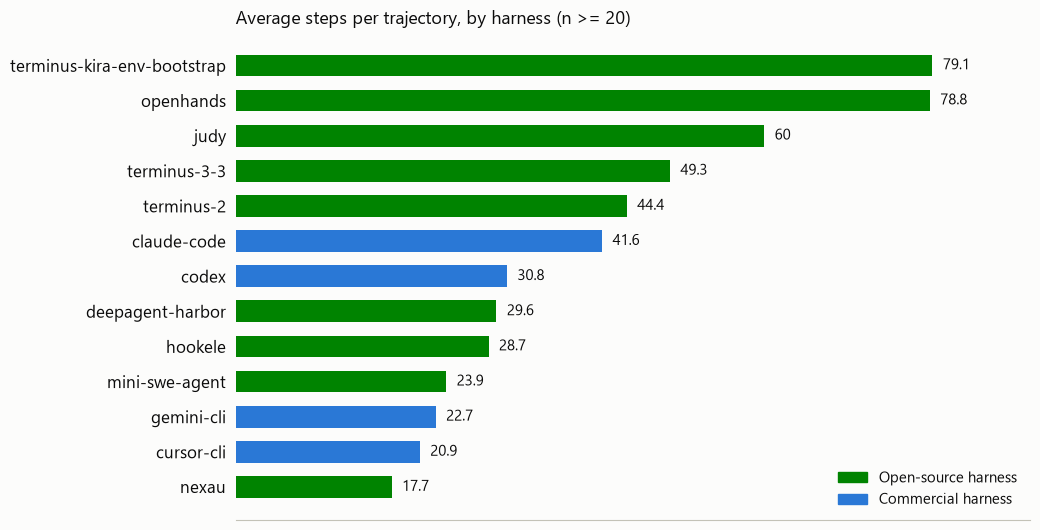

In [48]:
colors = [GREEN if hl == "open" else BLUE for hl in harness_rollup["harness_license"]]

fig, ax = plt.subplots(figsize=(10.5, 5.4))
bars = ax.barh(harness_rollup.index, harness_rollup["avg_steps"], color=colors, height=0.62)
_clean_axes(ax)
ax.tick_params(axis="y", labelsize=12)
vmax = harness_rollup["avg_steps"].max()
for b, v in zip(bars, harness_rollup["avg_steps"]):
    ax.text(v + vmax * 0.015, b.get_y() + b.get_height() / 2, f"{v:g}",
            va="center", ha="left", fontsize=11, color=INK)
ax.set_xlim(0, vmax * 1.14)
handles = [plt.Rectangle((0, 0), 1, 1, color=GREEN), plt.Rectangle((0, 0), 1, 1, color=BLUE)]
ax.legend(handles, ["Open-source harness", "Commercial harness"], loc="lower right", frameon=False, fontsize=10.5)
ax.set_title("Average steps per trajectory, by harness (n >= 20)", fontsize=13, color=INK, loc="left")
fig.tight_layout()
plt.show()

## Model rollup -- reasoning density by model, open-source vs. commercial

`pct_steps_with_thought` is the same metric `zest.stats` reports per
(source, agent) -- here collapsed across harness and source to compare
models directly. Floored at >= 15 trajectories; color marks license family
(commercial vs. open-source), never rank, per the fixed categorical order
established in `presentations/charts.py`.

In [49]:
model_rollup = (
    df[df["model"].notna()]
    .groupby(["model", "license"])
    .agg(n_trajectories=("n_steps", "count"), avg_steps=("n_steps", "mean"),
         median_steps=("n_steps", "median"),
         pct_steps_with_thought=("pct_thought", "mean"))
    .reset_index()
    .query("n_trajectories >= 15")
    .round(1)
)
model_rollup.sort_values("pct_steps_with_thought", ascending=False).head(15)

,model,license,n_trajectories,avg_steps,median_steps,pct_steps_with_thought
30,gpt-5.1-codex-mini,commercial,426,28.9,20.0,100.0
22,glm-5.1,open-source,431,32.1,24.0,71.4
0,MiniMax-M2.1,open-source,440,47.5,30.0,67.4
37,grok-4.5,commercial,405,20.9,15.0,60.3
9,claude-opus-4-8,commercial,539,18.6,14.0,48.9
3,claude-haiku-4-5-20251001,commercial,2453,55.1,36.0,46.6
20,gemini-3.1-pro-preview-customtools,commercial,443,24.5,18.0,43.4
32,gpt-5.5,commercial,1328,30.0,19.0,41.2
2,claude-fable-5,commercial,793,19.0,14.0,38.7
8,claude-opus-4-7,commercial,864,40.2,28.0,36.9


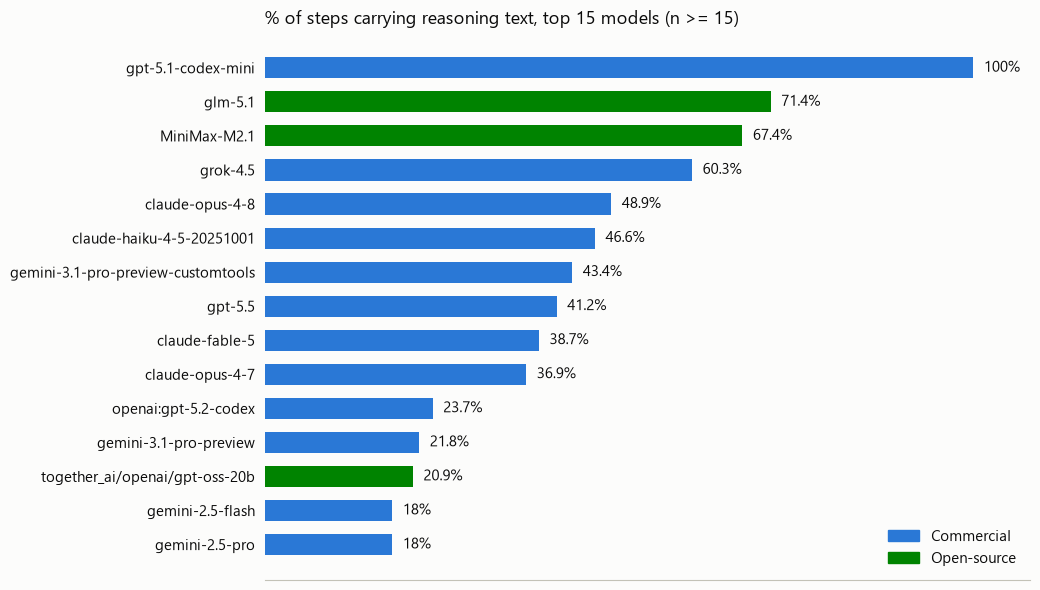

In [50]:
top = model_rollup.sort_values("pct_steps_with_thought", ascending=False).head(15).iloc[::-1]
colors = [GREEN if lic == "open-source" else BLUE for lic in top["license"]]

fig, ax = plt.subplots(figsize=(10.5, 6.0))
bars = ax.barh(top["model"], top["pct_steps_with_thought"], color=colors, height=0.62)
_clean_axes(ax)
ax.tick_params(axis="y", labelsize=11)
for b, v in zip(bars, top["pct_steps_with_thought"]):
    ax.text(v + 1.5, b.get_y() + b.get_height() / 2, f"{v:g}%",
            va="center", ha="left", fontsize=10.5, color=INK)
ax.set_xlim(0, 108)

handles = [plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=GREEN)]
ax.legend(handles, ["Commercial", "Open-source"], loc="lower right", frameon=False, fontsize=11)
ax.set_title("% of steps carrying reasoning text, top 15 models (n >= 15)", fontsize=13, color=INK, loc="left")
fig.tight_layout()
plt.show()

## License-family rollup

Two categories only, so a table carries as much information as a chart
would -- is the open-source vs. commercial gap above a real trend or an
artifact of which harnesses happen to run which models?

In [51]:
license_rollup = (
    df[df["license"] != "unknown"]
    .groupby("license")
    .agg(n_trajectories=("n_steps", "count"), pct_steps_with_thought=("pct_thought", "mean"))
    .round(1)
)
license_rollup

,n_trajectories,pct_steps_with_thought
license,,
commercial,28330,19.4
open-source,6282,13.7


## Token observability -- model licence x harness licence

This four-quadrant view follows Slide 7. Model licence is shown on the
horizontal axis, with commercial models in the left column. It includes only resolved
trajectories with reported, positive prompt and completion token counts.
For every quadrant, mean total tokens are displayed as:

`total tokens = prompt tokens + completion tokens`

The quadrant map and stacked bar chart report both components, the corresponding
total, medians, and eligibility coverage. Models without a confirmed commercial classification
are grouped with open-source models, following the project convention.

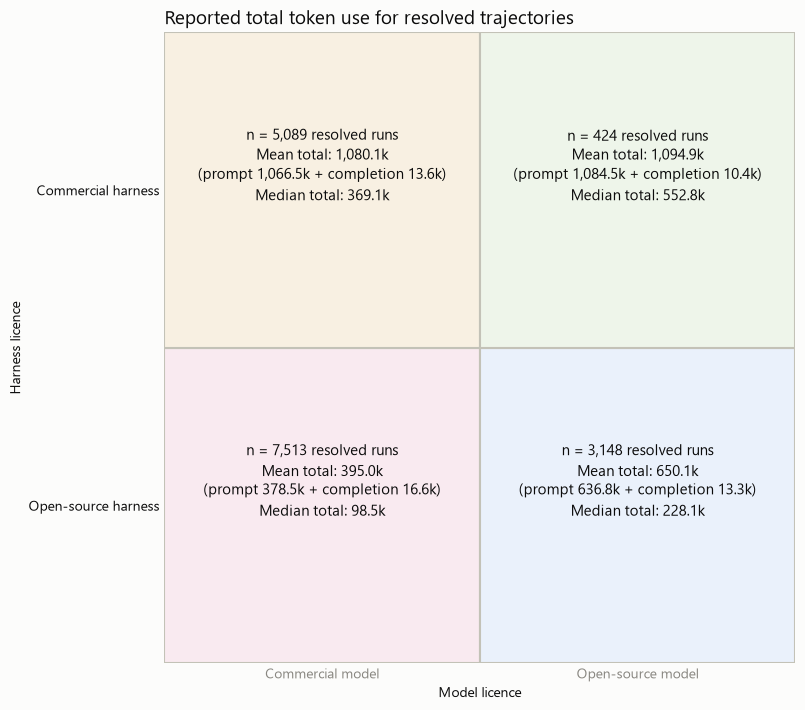

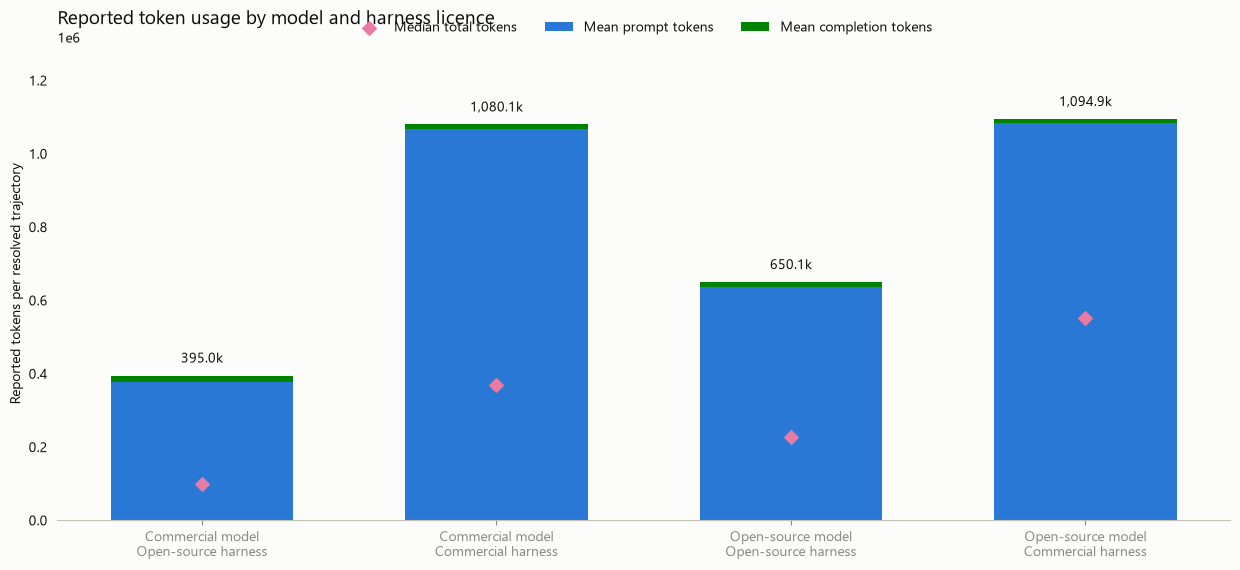

,model_license_4q,harness_license_4q,all_trajectories,resolved_trajectories,resolved_with_reported_tokens
0,commercial,open-source,18058,8408,7513
1,commercial,commercial,10272,5186,5089
2,open-source,open-source,11512,3413,3148
3,open-source,commercial,908,424,424


,model_license_4q,harness_license_4q,n_resolved,mean_prompt_tokens,mean_completion_tokens,mean_total_tokens,median_prompt_tokens,median_completion_tokens,median_total_tokens
0,commercial,open-source,7513,378471.9,16570.2,395042.2,83366.0,10333.0,98498.0
1,commercial,commercial,5089,1066507.1,13613.0,1080120.1,358720.0,7174.0,369067.0
2,open-source,open-source,3148,636811.7,13261.6,650073.3,215668.5,6546.0,228132.0
3,open-source,commercial,424,1084462.4,10439.3,1094901.7,548833.0,4832.0,552756.0


In [52]:
# Four-quadrant token analysis. Keep prompt and completion components
# separate so total usage remains auditable.
token_df = df.copy()
token_df["model_license_4q"] = token_df["license"].replace({"unknown": "open-source"})
token_df["harness_license_4q"] = token_df["harness"].map(harness_license).replace({"open": "open-source"})
token_df["total_tokens_from_parts"] = token_df["prompt_tokens"] + token_df["completion_tokens"]
token_df["token_components_reported"] = (
    token_df["prompt_tokens"].notna()
    & token_df["completion_tokens"].notna()
    & token_df["total_tokens_from_parts"].gt(0)
)
token_df["resolved_with_reported_tokens"] = (
    token_df["resolved"].eq(True) & token_df["token_components_reported"]
)

# Fixed display order: commercial models belong on the left.
QUADRANT_MODELS = ["commercial", "open-source"]
QUADRANT_HARNESSES = ["open-source", "commercial"]
quadrant_index = pd.MultiIndex.from_product(
    [QUADRANT_MODELS, QUADRANT_HARNESSES],
    names=["model_license_4q", "harness_license_4q"],
)

token_coverage = (
    token_df.groupby(["model_license_4q", "harness_license_4q"])
    .agg(
        all_trajectories=("n_steps", "count"),
        resolved_trajectories=("resolved", lambda s: s.eq(True).sum()),
        resolved_with_reported_tokens=("resolved_with_reported_tokens", "sum"),
    )
    .reindex(quadrant_index)
    .reset_index()
)

token_quadrants = (
    token_df[token_df["resolved_with_reported_tokens"]]
    .groupby(["model_license_4q", "harness_license_4q"])
    .agg(
        n_resolved=("n_steps", "count"),
        mean_prompt_tokens=("prompt_tokens", "mean"),
        mean_completion_tokens=("completion_tokens", "mean"),
        mean_total_tokens=("total_tokens_from_parts", "mean"),
        median_prompt_tokens=("prompt_tokens", "median"),
        median_completion_tokens=("completion_tokens", "median"),
        median_total_tokens=("total_tokens_from_parts", "median"),
    )
    .reindex(quadrant_index)
    .reset_index()
    .round(1)
)

if token_quadrants.isna().any().any():
    raise ValueError("At least one token quadrant has no eligible resolved trajectories.")


def _format_tokens(value):
    return f"{value / 1_000:,.1f}k"


quadrant_fills = {
    ("open-source", "open-source"): "#eaf1fb",
    ("open-source", "commercial"): "#eef5ea",
    ("commercial", "open-source"): "#f9eaf0",
    ("commercial", "commercial"): "#f8f0e2",
}
fig, ax = plt.subplots(figsize=(11.5, 7.2))
for x, model_license in enumerate(QUADRANT_MODELS):
    for y, harness_license_value in enumerate(QUADRANT_HARNESSES):
        row = token_quadrants[
            (token_quadrants["model_license_4q"] == model_license)
            & (token_quadrants["harness_license_4q"] == harness_license_value)
        ].iloc[0]
        ax.add_patch(plt.Rectangle(
            (x, y), 1, 1, facecolor=quadrant_fills[(model_license, harness_license_value)],
            edgecolor=BASELINE, linewidth=1.5,
        ))
        ax.text(
            x + 0.5, y + 0.58,
            f"n = {int(row['n_resolved']):,} resolved runs\n"
            f"Mean total: {_format_tokens(row['mean_total_tokens'])}\n"
            f"(prompt {_format_tokens(row['mean_prompt_tokens'])} + completion {_format_tokens(row['mean_completion_tokens'])})\n"
            f"Median total: {_format_tokens(row['median_total_tokens'])}",
            ha="center", va="center", fontsize=10.5, color=INK, linespacing=1.45,
        )

ax.set_xlim(0, 2)
ax.set_ylim(0, 2)
ax.set_xticks([0.5, 1.5], ["Commercial model", "Open-source model"])
ax.set_yticks([0.5, 1.5], ["Open-source harness", "Commercial harness"])
ax.set_xlabel("Model licence", color=INK)
ax.set_ylabel("Harness licence", color=INK)
ax.set_title("Reported total token use for resolved trajectories", fontsize=14, color=INK, loc="left")
ax.set_aspect("equal")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
fig.tight_layout()
plt.show()

# A conventional token-usage graph for the same four groups. Prompt and
# completion tokens are stacked; diamonds show median total tokens.
bar_order = [
    ("commercial", "open-source"),
    ("commercial", "commercial"),
    ("open-source", "open-source"),
    ("open-source", "commercial"),
]
bar_rows = (
    token_quadrants.set_index(["model_license_4q", "harness_license_4q"])
    .loc[bar_order]
    .reset_index()
)
bar_labels = [
    "Commercial model\nOpen-source harness",
    "Commercial model\nCommercial harness",
    "Open-source model\nOpen-source harness",
    "Open-source model\nCommercial harness",
]
x_positions = list(range(len(bar_rows)))
fig, ax = plt.subplots(figsize=(12.5, 5.8))
prompt_bars = ax.bar(
    x_positions, bar_rows["mean_prompt_tokens"],
    color=BLUE, width=0.62, label="Mean prompt tokens",
)
ax.bar(
    x_positions, bar_rows["mean_completion_tokens"],
    bottom=bar_rows["mean_prompt_tokens"], color=GREEN, width=0.62,
    label="Mean completion tokens",
)
ax.scatter(
    x_positions, bar_rows["median_total_tokens"],
    marker="D", s=48, color=MAGENTA, zorder=3, label="Median total tokens",
)
label_padding = bar_rows["mean_total_tokens"].max() * 0.025
for bar, total in zip(prompt_bars, bar_rows["mean_total_tokens"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2, total + label_padding,
        _format_tokens(total), ha="center", va="bottom", fontsize=10, color=INK,
    )
_clean_axes(ax)
ax.set_xticks(x_positions, bar_labels)
ax.set_ylabel("Reported tokens per resolved trajectory", color=INK)
ax.set_title("Reported token usage by model and harness licence", fontsize=14, color=INK, loc="left")
ax.legend(frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(0.5, 1.08))
ax.set_ylim(0, bar_rows["mean_total_tokens"].max() * 1.18)
fig.tight_layout()
plt.show()

display(token_coverage)
token_quadrants

## Cross-harness, same model


This chart rebuilds the comparison used in Slide 8 using only resolved
trajectories: GPT-5 Codex, GPT-5 Nano, and GPT-5 Mini under mini-swe-agent,
Codex, and Terminus-2. It reports mean steps, mean completion time, and
mean reported token use.

Completion time uses the downloaded source duration where available; the
supporting table flags any normalized-timestamp fallback. The table also
reports medians as robustness checks. The token figure uses the same resolved
model-harness combinations and includes runs with both prompt and completion
token counts; each label shows total = prompt + completion.

In [53]:
pivot = (
    df[df["model"].notna()]
    .groupby(["model", "harness"])
    .agg(n_trajectories=("n_steps", "count"), avg_steps=("n_steps", "mean"),
         median_steps=("n_steps", "median"))
    .reset_index()
    .query("n_trajectories >= 30")
    .round(1)
)
harness_counts = pivot.groupby("model")["harness"].nunique().sort_values(ascending=False)
cross_harness_models = harness_counts[harness_counts > 1]
print(f"{len(cross_harness_models)} models run under >1 harness (n >= 30 each)")
cross_harness_models.head(10)

# Cross-harness figures below use resolved trajectories only. Completion
# time prefers the downloaded source duration and falls back to normalized
# timestamps only when that source value is unavailable.
resolved_pivot = (
    known[known["resolved"]]
    .groupby(["model", "harness"])
    .agg(
        n_resolved=("n_steps", "count"),
        avg_steps=("n_steps", "mean"),
        median_steps=("n_steps", "median"),
        n_completion_times=("completion_duration_min", "count"),
        avg_completion_time_min=("completion_duration_min", "mean"),
        median_completion_time_min=("completion_duration_min", "median"),
        n_external_completion_times=(
            "completion_duration_source",
            lambda s: (s == "downloaded_metadata").sum(),
        ),
    )
    .reset_index()
    .query("n_resolved >= 30")
    .round(1)
)
print(f"{len(resolved_pivot)} resolved model-harness groups with n >= 30")


def plot_resolved_harness_comparison(data, models, harnesses, labels, title, figsize):
    """Plot mean steps and completion time for resolved trajectories only."""
    x = list(range(len(models)))
    width = 0.24
    colors = [BLUE, GREEN, MAGENTA]
    metrics = [
        ("avg_steps", "Mean steps per resolved trajectory", "Mean steps"),
        ("avg_completion_time_min", "Mean completion time (minutes)", "Mean completion time"),
    ]

    fig, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, (metric, ylabel, panel_title) in zip(axes, metrics):
        values = data.pivot(index="model", columns="harness", values=metric).reindex(
            index=models, columns=harnesses
        )
        label_padding = max(float(values.max().max()) * 0.02, 0.25)
        for offset, (harness, color) in enumerate(zip(harnesses, colors)):
            positions = [value + (offset - 1) * width for value in x]
            bars = ax.bar(positions, values[harness], width=width, label=harness, color=color)
            for bar, value in zip(bars, values[harness]):
                ax.text(bar.get_x() + bar.get_width() / 2, value + label_padding, f"{value:.1f}",
                        ha="center", va="bottom", fontsize=9.5, color=INK)
        _clean_axes(ax)
        ax.set_xticks(x, labels)
        ax.set_ylabel(ylabel, color=INK)
        ax.set_title(panel_title, fontsize=12, color=INK, loc="left")

    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, frameon=False, ncols=3, loc="upper center",
               bbox_to_anchor=(0.5, 1.03))
    fig.suptitle(title, fontsize=13, color=INK, x=0.06, ha="left", y=1.08)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()


def resolved_comparison_table(data):
    table = data.copy()
    table["completion_time_source"] = table.apply(
        lambda row: (
            "downloaded metadata"
            if row["n_external_completion_times"] == row["n_completion_times"]
            else (
                "normalized timestamps"
                if row["n_external_completion_times"] == 0
                else "downloaded metadata + fallback"
            )
        ),
        axis=1,
    )
    return table[[
        "model", "harness", "n_resolved", "avg_steps", "median_steps",
        "avg_completion_time_min", "median_completion_time_min",
        "n_completion_times", "n_external_completion_times",
        "completion_time_source",
    ]]


def resolved_token_rollup(models, harnesses):
    """Summarize reported token use for the requested resolved combinations."""
    resolved = known[
        known["resolved"]
        & known["model"].isin(models)
        & known["harness"].isin(harnesses)
    ].copy()
    resolved_counts = (
        resolved.groupby(["model", "harness"])
        .size()
        .rename("n_resolved")
        .reset_index()
    )

    reported = resolved[
        resolved["prompt_tokens"].notna()
        & resolved["completion_tokens"].notna()
    ].copy()
    reported["reported_total_tokens"] = (
        reported["prompt_tokens"] + reported["completion_tokens"]
    )
    reported = reported[reported["reported_total_tokens"] > 0]

    token_summary = (
        reported.groupby(["model", "harness"])
        .agg(
            n_token_resolved=("reported_total_tokens", "size"),
            mean_prompt_tokens=("prompt_tokens", "mean"),
            mean_completion_tokens=("completion_tokens", "mean"),
            mean_total_tokens=("reported_total_tokens", "mean"),
            median_prompt_tokens=("prompt_tokens", "median"),
            median_completion_tokens=("completion_tokens", "median"),
            median_total_tokens=("reported_total_tokens", "median"),
        )
        .reset_index()
    )

    grid = pd.MultiIndex.from_product(
        [models, harnesses], names=["model", "harness"]
    ).to_frame(index=False)
    summary = (
        grid.merge(resolved_counts, on=["model", "harness"], how="left")
        .merge(token_summary, on=["model", "harness"], how="left")
    )
    if summary["n_resolved"].isna().any():
        raise ValueError("One or more requested combinations have no resolved runs.")
    summary["n_token_resolved"] = summary["n_token_resolved"].fillna(0)
    summary["token_coverage_pct"] = (
        100 * summary["n_token_resolved"] / summary["n_resolved"]
    )
    summary[["n_resolved", "n_token_resolved"]] = summary[[
        "n_resolved", "n_token_resolved"
    ]].astype(int)
    return summary.round(1)


def plot_resolved_token_comparison(data, models, harnesses, labels, title, figsize):
    """Plot mean reported total tokens with prompt/completion components."""
    x = list(range(len(models)))
    width = 0.24
    colors = [BLUE, GREEN, MAGENTA]
    total = data.pivot(index="model", columns="harness", values="mean_total_tokens").reindex(
        index=models, columns=harnesses
    )
    prompt = data.pivot(index="model", columns="harness", values="mean_prompt_tokens").reindex(
        index=models, columns=harnesses
    )
    completion = data.pivot(
        index="model", columns="harness", values="mean_completion_tokens"
    ).reindex(index=models, columns=harnesses)

    fig, ax = plt.subplots(figsize=figsize)
    maximum = float(total.max().max())
    label_padding = max(maximum * 0.018, 1.0)
    for offset, (harness, color) in enumerate(zip(harnesses, colors)):
        positions = [
            value + (offset - (len(harnesses) - 1) / 2) * width for value in x
        ]
        bars = ax.bar(positions, total[harness], width=width, label=harness, color=color)
        for bar, total_value, prompt_value, completion_value in zip(
            bars, total[harness], prompt[harness], completion[harness]
        ):
            if pd.isna(total_value):
                ax.text(
                    bar.get_x() + bar.get_width() / 2, maximum * 0.035,
                    "N/A\n(no reported tokens)", ha="center", va="bottom",
                    fontsize=8.3, color=MUTED,
                )
                continue
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                total_value + label_padding,
                f"{_format_tokens(total_value)}\n"
                f"(P {_format_tokens(prompt_value)} + C {_format_tokens(completion_value)})",
                ha="center", va="bottom", fontsize=8.5, color=INK,
            )

    _clean_axes(ax)
    ax.set_xticks(x, labels)
    ax.set_ylabel("Mean tokens per resolved trajectory", color=INK)
    ax.yaxis.set_major_formatter(lambda value, _: _format_tokens(value))
    ax.set_ylim(0, maximum * 1.24)
    ax.set_title(title, fontsize=13, color=INK, loc="left", pad=18)
    ax.legend(frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(0.5, 1.02))
    fig.tight_layout()
    plt.show()

18 models run under >1 harness (n >= 30 each)
76 resolved model-harness groups with n >= 30


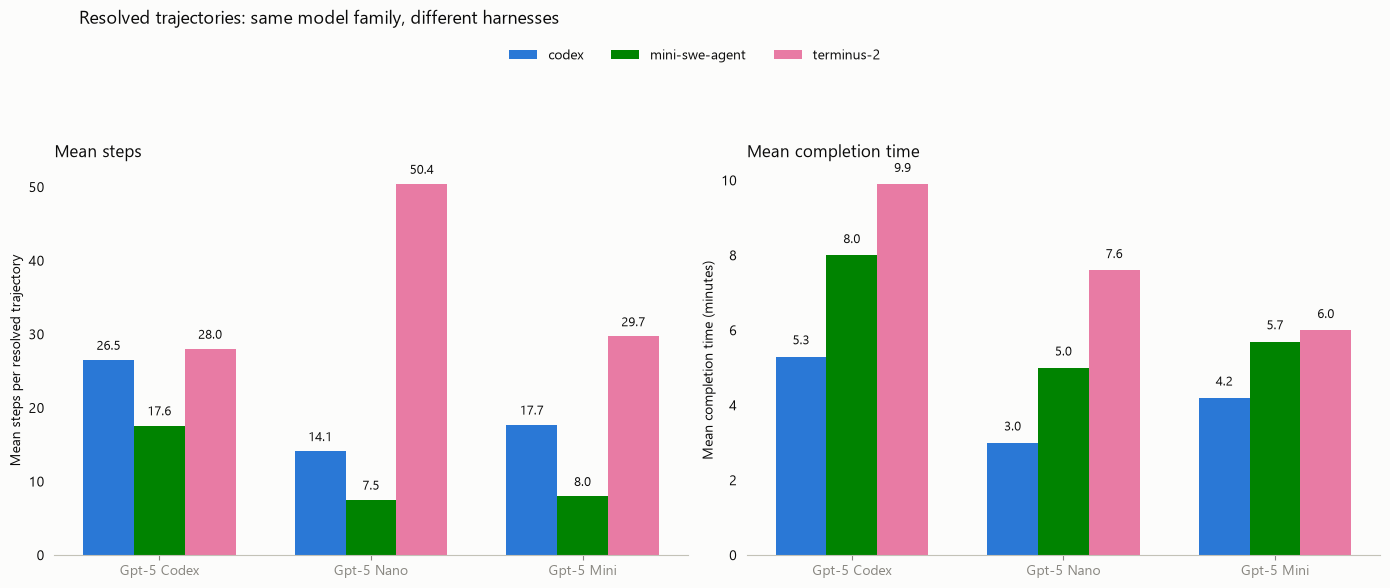

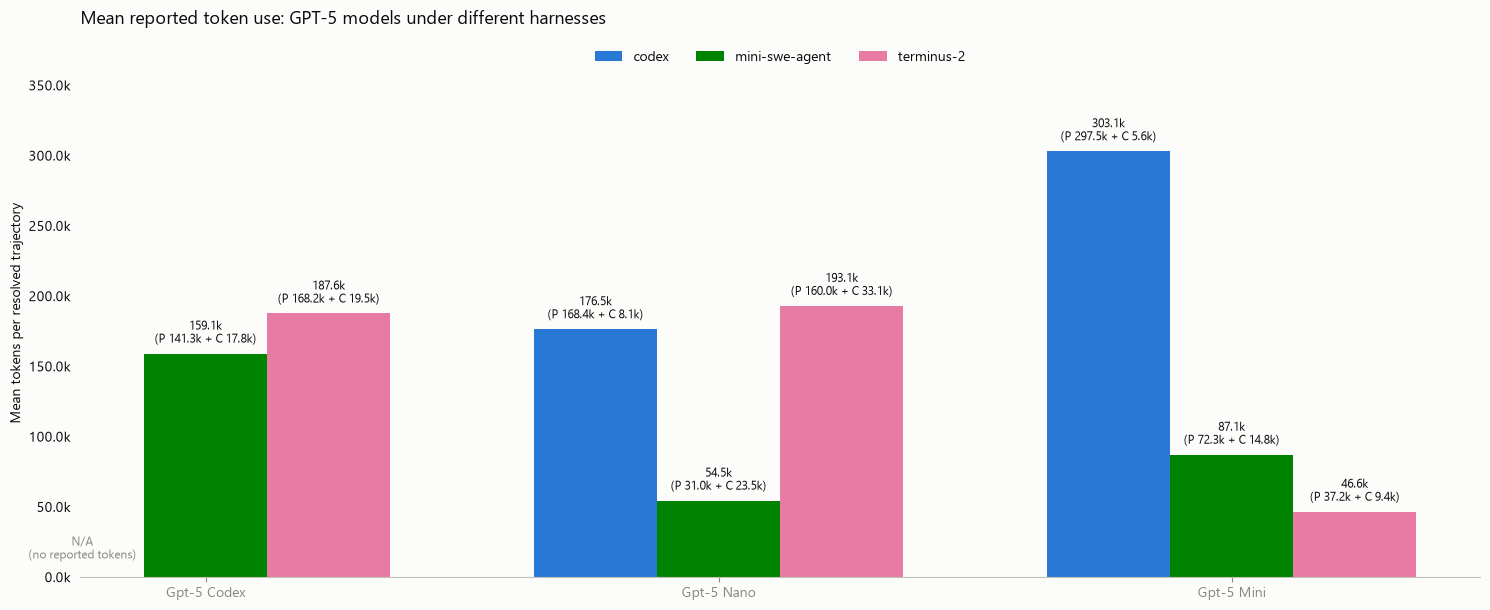

,model,harness,n_resolved,avg_steps,median_steps,avg_completion_time_min,median_completion_time_min,n_completion_times,n_external_completion_times,completion_time_source
0,gpt-5-codex,codex,71,26.5,20.0,5.3,2.4,71,0,normalized timestamps
1,gpt-5-codex,mini-swe-agent,184,17.6,13.0,8.0,5.9,184,184,downloaded metadata
2,gpt-5-codex,terminus-2,193,28.0,20.0,9.9,6.5,193,193,downloaded metadata
3,gpt-5-nano,codex,51,14.1,12.0,3.0,2.1,51,51,downloaded metadata
4,gpt-5-nano,mini-swe-agent,31,7.5,5.0,5.0,3.8,31,31,downloaded metadata
5,gpt-5-nano,terminus-2,35,50.4,23.0,7.6,4.7,35,35,downloaded metadata
6,gpt-5-mini,codex,138,17.7,13.0,4.2,2.3,138,138,downloaded metadata
7,gpt-5-mini,mini-swe-agent,99,8.0,5.0,5.7,3.9,99,99,downloaded metadata
8,gpt-5-mini,terminus-2,107,29.7,21.0,6.0,4.0,107,107,downloaded metadata


,model,harness,n_resolved,n_token_resolved,mean_prompt_tokens,mean_completion_tokens,mean_total_tokens,median_prompt_tokens,median_completion_tokens,median_total_tokens,token_coverage_pct
0,gpt-5-codex,codex,71,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,gpt-5-codex,mini-swe-agent,184,184,141324.5,17803.3,159127.8,44747.0,11988.5,60327.0,100.0
2,gpt-5-codex,terminus-2,193,193,168162.1,19486.6,187648.7,59674.0,12877.0,80904.0,100.0
3,gpt-5-nano,codex,51,51,168359.7,8093.2,176452.9,134835.0,8610.0,140875.0,100.0
4,gpt-5-nano,mini-swe-agent,31,31,31006.5,23468.2,54474.7,14944.0,20497.0,30722.0,100.0
5,gpt-5-nano,terminus-2,35,35,159982.5,33080.9,193063.4,31032.0,19743.0,50937.0,100.0
6,gpt-5-mini,codex,138,138,297541.6,5594.5,303136.1,119053.5,4264.5,123111.5,100.0
7,gpt-5-mini,mini-swe-agent,99,99,72305.7,14842.2,87147.9,17884.0,9435.0,28327.0,100.0
8,gpt-5-mini,terminus-2,107,107,37235.3,9352.4,46587.7,12956.0,6949.0,21128.0,100.0


In [54]:
# Rebuilt version of presentation Slide 8: resolved trajectories only.
SLIDE8_MODELS = ["gpt-5-codex", "gpt-5-nano", "gpt-5-mini"]
SLIDE8_HARNESSES = ["codex", "mini-swe-agent", "terminus-2"]

slide8_data = (
    resolved_pivot[
        resolved_pivot["model"].isin(SLIDE8_MODELS)
        & resolved_pivot["harness"].isin(SLIDE8_HARNESSES)
    ]
    .set_index(["model", "harness"])
    .reindex(pd.MultiIndex.from_product([SLIDE8_MODELS, SLIDE8_HARNESSES], names=["model", "harness"]))
    .reset_index()
)
if slide8_data[[
    "n_resolved", "avg_steps", "median_steps",
    "avg_completion_time_min", "median_completion_time_min",
]].isna().any().any():
    raise ValueError("One or more Slide 8 model-harness combinations are missing.")

plot_resolved_harness_comparison(
    slide8_data,
    SLIDE8_MODELS,
    SLIDE8_HARNESSES,
    [model.replace("gpt-5-", "GPT-5 ").title() for model in SLIDE8_MODELS],
    "Resolved trajectories: same model family, different harnesses",
    figsize=(14, 5.4),
)

slide8_token_data = resolved_token_rollup(SLIDE8_MODELS, SLIDE8_HARNESSES)
plot_resolved_token_comparison(
    slide8_token_data,
    SLIDE8_MODELS,
    SLIDE8_HARNESSES,
    [model.replace("gpt-5-", "GPT-5 " ).title() for model in SLIDE8_MODELS],
    "Mean reported token use: GPT-5 models under different harnesses",
    figsize=(15, 6.2),
)

display(resolved_comparison_table(slide8_data))
slide8_token_data

## Additional cross-harness example -- Gemini 2.5

This independent comparison holds each Gemini 2.5 model variant constant
while changing the harness. It includes only resolved trajectories under
Gemini CLI, mini-swe-agent, and Terminus-2, and reports both mean steps and
mean completion time. A second figure reports mean total tokens as prompt +
completion for the same combinations and resolved-run filter.

The tables include medians, completion-time provenance, and reported-token
coverage.

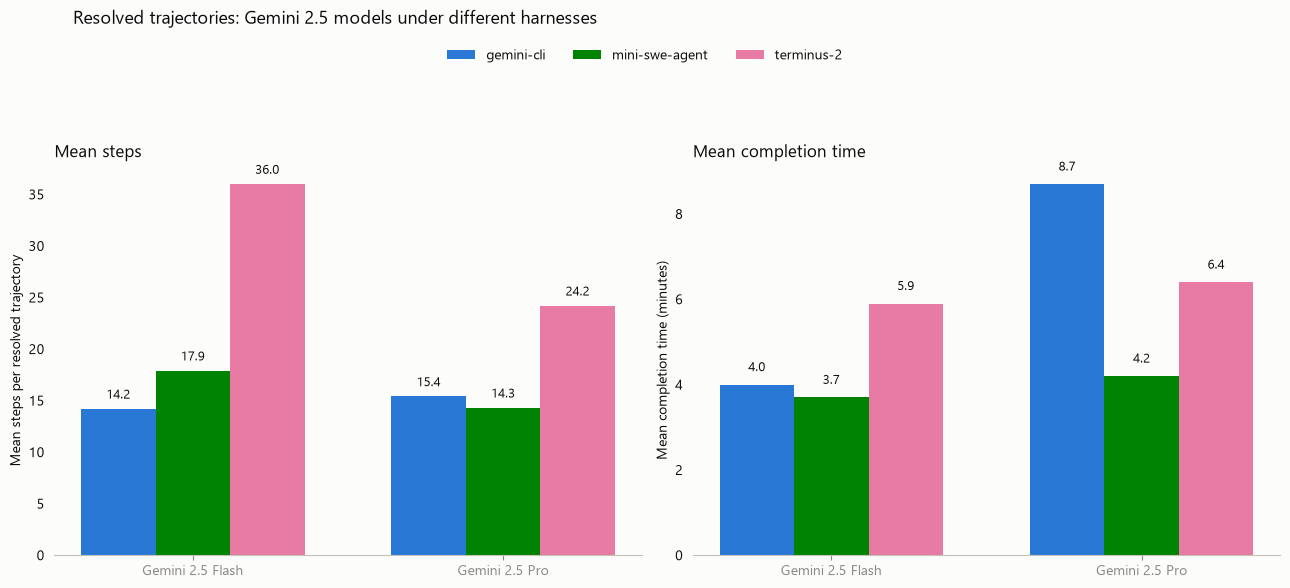

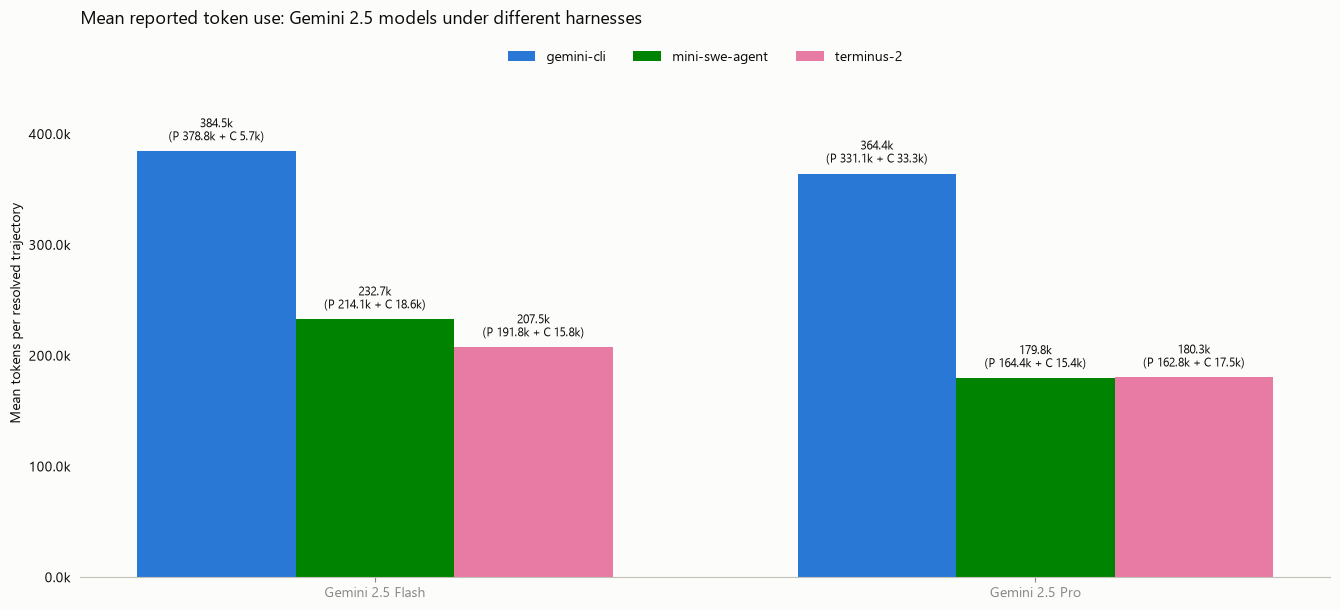

,model,harness,n_resolved,avg_steps,median_steps,avg_completion_time_min,median_completion_time_min,n_completion_times,n_external_completion_times,completion_time_source
0,gemini-2.5-flash,gemini-cli,68,14.2,11.0,4.0,2.4,68,68,downloaded metadata
1,gemini-2.5-flash,mini-swe-agent,76,17.9,13.5,3.7,1.8,76,76,downloaded metadata
2,gemini-2.5-flash,terminus-2,75,36.0,23.0,5.9,3.6,75,75,downloaded metadata
3,gemini-2.5-pro,gemini-cli,85,15.4,12.0,8.7,8.0,85,85,downloaded metadata
4,gemini-2.5-pro,mini-swe-agent,116,14.3,11.0,4.2,3.0,116,116,downloaded metadata
5,gemini-2.5-pro,terminus-2,145,24.2,15.0,6.4,4.1,145,145,downloaded metadata


,model,harness,n_resolved,n_token_resolved,mean_prompt_tokens,mean_completion_tokens,mean_total_tokens,median_prompt_tokens,median_completion_tokens,median_total_tokens,token_coverage_pct
0,gemini-2.5-flash,gemini-cli,68,68,378837.5,5650.8,384488.3,138301.5,3948.0,141453.5,100.0
1,gemini-2.5-flash,mini-swe-agent,76,76,214143.8,18552.3,232696.1,55676.0,4884.5,63663.5,100.0
2,gemini-2.5-flash,terminus-2,75,75,191784.4,15759.3,207543.7,54474.0,9886.0,71211.0,100.0
3,gemini-2.5-pro,gemini-cli,85,85,331099.6,33296.2,364395.8,153027.0,12758.0,202214.0,100.0
4,gemini-2.5-pro,mini-swe-agent,116,116,164364.2,15400.0,179764.2,46874.5,10209.0,63505.0,100.0
5,gemini-2.5-pro,terminus-2,145,145,162782.8,17509.2,180292.0,46488.0,13502.0,57011.0,100.0


In [55]:
# Additional example: resolved Gemini 2.5 trajectories under three harnesses.
GEMINI_MODELS = ["gemini-2.5-flash", "gemini-2.5-pro"]
GEMINI_HARNESSES = ["gemini-cli", "mini-swe-agent", "terminus-2"]

gemini_data = (
    resolved_pivot[
        resolved_pivot["model"].isin(GEMINI_MODELS)
        & resolved_pivot["harness"].isin(GEMINI_HARNESSES)
    ]
    .set_index(["model", "harness"])
    .reindex(pd.MultiIndex.from_product([GEMINI_MODELS, GEMINI_HARNESSES], names=["model", "harness"]))
    .reset_index()
)
if gemini_data[[
    "n_resolved", "avg_steps", "median_steps",
    "avg_completion_time_min", "median_completion_time_min",
]].isna().any().any():
    raise ValueError("One or more Gemini model-harness combinations are missing.")

plot_resolved_harness_comparison(
    gemini_data,
    GEMINI_MODELS,
    GEMINI_HARNESSES,
    ["Gemini 2.5 Flash", "Gemini 2.5 Pro"],
    "Resolved trajectories: Gemini 2.5 models under different harnesses",
    figsize=(13, 5.4),
)

gemini_token_data = resolved_token_rollup(GEMINI_MODELS, GEMINI_HARNESSES)
plot_resolved_token_comparison(
    gemini_token_data,
    GEMINI_MODELS,
    GEMINI_HARNESSES,
    ["Gemini 2.5 Flash", "Gemini 2.5 Pro"],
    "Mean reported token use: Gemini 2.5 models under different harnesses",
    figsize=(13.5, 6.2),
)

display(resolved_comparison_table(gemini_data))
gemini_token_data

In [56]:
cross_harness_table = (
    pivot[pivot["model"].isin(cross_harness_models.index)]
    .merge(cross_harness_models.rename("n_harnesses"), left_on="model", right_index=True)
    .sort_values(["n_harnesses", "model", "n_trajectories"], ascending=[False, True, False])
)
cross_harness_table

,model,harness,n_trajectories,avg_steps,median_steps,n_harnesses
12,claude-opus-4-6,terminus-2,445,31.4,20.0,4
14,claude-opus-4-6,terminus-kira-env-bootstrap,445,79.1,51.0,4
11,claude-opus-4-6,claude-code,435,42.3,32.0,4
13,claude-opus-4-6,terminus-3-3,389,59.3,42.0,4
4,claude-haiku-4-5-20251001,claude-code,1587,60.3,41.0,3
6,claude-haiku-4-5-20251001,terminus-2,438,51.1,34.0,3
5,claude-haiku-4-5-20251001,mini-swe-agent,428,40.1,22.5,3
27,gemini-2.5-flash,terminus-2,437,79.0,30.0,3
26,gemini-2.5-flash,mini-swe-agent,432,42.5,17.5,3
25,gemini-2.5-flash,gemini-cli,405,14.9,9.0,3


## Presentation-ready verification (Slides 3--8)

This section recomputes the presentation statistics directly from the current
curated Terminal-Bench 2.0 and 2.1 files. The two corpora are never pooled in
these tables or charts.

Definitions used throughout:

- **Trajectory**: one normalized JSONL trajectory record.
- **Model and harness counts**: counted separately; an agent is not treated as
  a single combined model--harness entity.
- **Open-source category**: includes records previously labelled `unknown`, in
  accordance with the project's presentation coding rule.
- **Mean/median steps**: calculated per trajectory. Medians are included because
  the distributions are skewed.
- **Resolved results**: use only records whose outcome is available.
- **Reported tokens**: use resolved trajectories with both prompt and completion
  token fields. Coverage is always shown beside token summaries.


In [ ]:
PRESENTATION_SOURCE_ORDER = list(SOURCES.values())

presentation_df = df.copy()
presentation_df["model_license_presentation"] = presentation_df["license"].replace(
    {"unknown": "open-source"}
)
presentation_df["model_display"] = presentation_df["model"].fillna("unknown/unreported")
presentation_df["harness_license_presentation"] = (
    presentation_df["harness"].map(harness_license).replace({"open": "open-source"})
)
presentation_df["reported_total_tokens"] = (
    presentation_df["prompt_tokens"] + presentation_df["completion_tokens"]
)
presentation_df["has_reported_token_components"] = (
    presentation_df["prompt_tokens"].notna()
    & presentation_df["completion_tokens"].notna()
    & presentation_df["reported_total_tokens"].gt(0)
)

# Slide 3: corpus inventory. Named model counts exclude missing model names;
# the number of missing names is shown explicitly instead of silently assigning
# them to a fake model.
presentation_inventory = (
    presentation_df.groupby("source_label")
    .agg(
        trajectories=("n_steps", "size"),
        unique_tasks=("task_id", "nunique"),
        harnesses=("harness", "nunique"),
        named_models=("model", "nunique"),
        missing_model_names=("model", lambda s: s.isna().sum()),
        known_outcomes=("resolved_available", "sum"),
        resolved_runs=("resolved", lambda s: s.eq(True).sum()),
        mean_steps=("n_steps", "mean"),
        median_steps=("n_steps", "median"),
    )
    .reindex(PRESENTATION_SOURCE_ORDER)
)
presentation_inventory["outcome_coverage_pct"] = (
    100 * presentation_inventory["known_outcomes"] / presentation_inventory["trajectories"]
)
presentation_inventory["pass_rate_known_pct"] = (
    100 * presentation_inventory["resolved_runs"] / presentation_inventory["known_outcomes"]
)
presentation_inventory = presentation_inventory.round(1)
display(presentation_inventory)

# Slide 4: harness-level step statistics, separately for TB 2.0 and TB 2.1.
slide4_harness_stats = (
    presentation_df.groupby(["source_label", "harness"])
    .agg(
        trajectories=("n_steps", "size"),
        named_models=("model", "nunique"),
        known_outcomes=("resolved_available", "sum"),
        resolved_runs=("resolved", lambda s: s.eq(True).sum()),
        mean_steps=("n_steps", "mean"),
        median_steps=("n_steps", "median"),
    )
    .reset_index()
)
slide4_harness_stats["outcome_coverage_pct"] = (
    100 * slide4_harness_stats["known_outcomes"] / slide4_harness_stats["trajectories"]
)
slide4_harness_stats["pass_rate_known_pct"] = (
    100 * slide4_harness_stats["resolved_runs"] / slide4_harness_stats["known_outcomes"]
)
slide4_harness_stats["harness_license"] = (
    slide4_harness_stats["harness"].map(harness_license).replace({"open": "open-source"})
)
slide4_harness_stats = slide4_harness_stats.round(1)
display(slide4_harness_stats.sort_values(["source_label", "mean_steps"], ascending=[True, False]))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
for ax, source_label in zip(axes, PRESENTATION_SOURCE_ORDER):
    plot_data = (
        slide4_harness_stats[slide4_harness_stats["source_label"] == source_label]
        .sort_values("mean_steps")
    )
    colors = plot_data["harness_license"].map({"open-source": GREEN, "commercial": BLUE})
    bars = ax.barh(plot_data["harness"], plot_data["mean_steps"], color=colors, height=0.62)
    _clean_axes(ax)
    xmax = max(float(plot_data["mean_steps"].max()), 1.0)
    for bar, mean, median in zip(bars, plot_data["mean_steps"], plot_data["median_steps"]):
        ax.text(mean + xmax * 0.018, bar.get_y() + bar.get_height() / 2,
                f"mean {mean:.1f} | median {median:.1f}", va="center", fontsize=8.5)
    ax.set_xlim(0, xmax * 1.38)
    ax.set_title(source_label, loc="left", fontsize=13)
    ax.set_xlabel("Steps per trajectory")
fig.suptitle("Slide 4 verification: step count by harness and benchmark", x=0.05, ha="left", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

def _license_step_rollup(license_column):
    return (
        presentation_df.groupby(["source_label", license_column])
        .agg(
            trajectories=("n_steps", "size"),
            mean_steps=("n_steps", "mean"),
            median_steps=("n_steps", "median"),
        )
        .reset_index()
        .round(1)
    )

slide5_harness_license_stats = _license_step_rollup("harness_license_presentation")
slide6_model_license_stats = _license_step_rollup("model_license_presentation")
display(slide5_harness_license_stats)
display(slide6_model_license_stats)

def plot_license_steps(summary, license_column, title):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
    order = ["commercial", "open-source"]
    for ax, source_label in zip(axes, PRESENTATION_SOURCE_ORDER):
        plot_data = (
            summary[summary["source_label"] == source_label]
            .set_index(license_column)
            .reindex(order)
        )
        bars = ax.bar(order, plot_data["mean_steps"], color=[BLUE, GREEN], width=0.58)
        ymax = max(float(plot_data["mean_steps"].max()), 1.0)
        for bar, mean, median, n in zip(
            bars, plot_data["mean_steps"], plot_data["median_steps"], plot_data["trajectories"]
        ):
            ax.text(bar.get_x() + bar.get_width() / 2, mean + ymax * 0.025,
                    f"mean {mean:.1f}\nmedian {median:.1f}\nn={int(n):,}",
                    ha="center", va="bottom", fontsize=9)
        _clean_axes(ax, keep_xticks=True)
        ax.set_ylim(0, ymax * 1.35)
        ax.set_title(source_label, loc="left", fontsize=12)
        ax.set_ylabel("Steps per trajectory")
    fig.suptitle(title, x=0.05, ha="left", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

plot_license_steps(
    slide5_harness_license_stats,
    "harness_license_presentation",
    "Slide 5 verification: open-source vs. commercial harnesses",
)
plot_license_steps(
    slide6_model_license_stats,
    "model_license_presentation",
    "Slide 6 verification: open-source vs. commercial models",
)

# Slide 8: the current same-model/different-harness comparison, now with
# corpus provenance and both mean and median values.
slide8_by_corpus = (
    presentation_df[
        presentation_df["resolved"].eq(True)
        & presentation_df["model"].isin(SLIDE8_MODELS)
        & presentation_df["harness"].isin(SLIDE8_HARNESSES)
    ]
    .groupby(["source_label", "model", "harness"])
    .agg(
        resolved_runs=("n_steps", "size"),
        mean_steps=("n_steps", "mean"),
        median_steps=("n_steps", "median"),
        mean_completion_time_min=("completion_duration_min", "mean"),
        median_completion_time_min=("completion_duration_min", "median"),
    )
    .reset_index()
    .round(1)
)
display(slide8_by_corpus.sort_values(["source_label", "model", "harness"]))


### Reported token usage across harnesses and models

Token statistics below are restricted to resolved trajectories that report
both components. `Total = prompt + completion`. Means describe total workload;
medians show a typical run and are more resistant to extreme trajectories.
The coverage columns must remain visible when these values are presented.


In [ ]:
resolved_for_tokens = presentation_df[presentation_df["resolved"].eq(True)].copy()
reported_resolved_tokens = resolved_for_tokens[
    resolved_for_tokens["has_reported_token_components"]
].copy()

token_coverage_by_source = (
    resolved_for_tokens.groupby("source_label")
    .agg(
        resolved_runs=("n_steps", "size"),
        token_reported_runs=("has_reported_token_components", "sum"),
    )
    .reindex(PRESENTATION_SOURCE_ORDER)
)
token_coverage_by_source["token_coverage_pct"] = (
    100 * token_coverage_by_source["token_reported_runs"]
    / token_coverage_by_source["resolved_runs"]
)
token_coverage_by_source = token_coverage_by_source.round(1)
display(token_coverage_by_source)

def token_rollup_by(group_column):
    resolved_counts = (
        resolved_for_tokens.groupby(["source_label", group_column])
        .size()
        .rename("resolved_runs")
        .reset_index()
    )
    reported = (
        reported_resolved_tokens.groupby(["source_label", group_column])
        .agg(
            token_reported_runs=("reported_total_tokens", "size"),
            mean_prompt_tokens=("prompt_tokens", "mean"),
            mean_completion_tokens=("completion_tokens", "mean"),
            mean_total_tokens=("reported_total_tokens", "mean"),
            median_prompt_tokens=("prompt_tokens", "median"),
            median_completion_tokens=("completion_tokens", "median"),
            median_total_tokens=("reported_total_tokens", "median"),
        )
        .reset_index()
    )
    result = resolved_counts.merge(reported, on=["source_label", group_column], how="left")
    result["token_reported_runs"] = result["token_reported_runs"].fillna(0).astype(int)
    result["token_coverage_pct"] = (
        100 * result["token_reported_runs"] / result["resolved_runs"]
    )
    return result.round(1)

token_by_harness = token_rollup_by("harness")
token_by_model = token_rollup_by("model_display")
display(token_by_harness.sort_values(["source_label", "mean_total_tokens"], ascending=[True, False]))
display(token_by_model.sort_values(["source_label", "mean_total_tokens"], ascending=[True, False]))

def plot_token_breakdown(summary, group_column, title, minimum_reported=20, top_n=None):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7.2))
    for ax, source_label in zip(axes, PRESENTATION_SOURCE_ORDER):
        plot_data = summary[
            (summary["source_label"] == source_label)
            & (summary["token_reported_runs"] >= minimum_reported)
        ].copy()
        if top_n is not None and len(plot_data) > top_n:
            plot_data = plot_data.nlargest(top_n, "token_reported_runs")
        plot_data = plot_data.sort_values("mean_total_tokens")
        ax.barh(plot_data[group_column], plot_data["mean_prompt_tokens"],
                color=BLUE, label="Mean prompt tokens")
        ax.barh(plot_data[group_column], plot_data["mean_completion_tokens"],
                left=plot_data["mean_prompt_tokens"], color=MAGENTA,
                label="Mean completion tokens")
        ax.scatter(plot_data["median_total_tokens"], plot_data[group_column],
                   color=INK, marker="D", s=24, label="Median total", zorder=3)
        _clean_axes(ax)
        ax.xaxis.set_major_formatter(lambda value, _: _format_tokens(value))
        ax.set_xlabel("Reported tokens per resolved trajectory")
        ax.set_title(source_label, loc="left", fontsize=12)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(0.5, 0.99))
    fig.suptitle(title, x=0.04, ha="left", y=1.03, fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

plot_token_breakdown(
    token_by_harness, "harness",
    "Reported token usage by harness (resolved runs; n with tokens >= 20)",
)
plot_token_breakdown(
    token_by_model, "model_display",
    "Reported token usage by model (top 12 by covered resolved runs)",
    top_n=12,
)

# Four model-licence x harness-licence combinations, kept separate by corpus.
token_four_quadrants_by_source = (
    reported_resolved_tokens.groupby([
        "source_label", "model_license_presentation", "harness_license_presentation"
    ])
    .agg(
        token_reported_runs=("reported_total_tokens", "size"),
        mean_prompt_tokens=("prompt_tokens", "mean"),
        mean_completion_tokens=("completion_tokens", "mean"),
        mean_total_tokens=("reported_total_tokens", "mean"),
        median_total_tokens=("reported_total_tokens", "median"),
    )
    .reset_index()
    .round(1)
)
display(token_four_quadrants_by_source.sort_values([
    "source_label", "model_license_presentation", "harness_license_presentation"
]))


## Save summary

Writes the lightweight per-trajectory table so other analyses can reuse the
curated rollups without rereading full trajectory steps.

In [57]:
out_path = DATA_DIR / "cross_corpus_summary.csv"
df.to_csv(out_path, index=False)
print(f"saved {len(df):,} rows -> {out_path}")

saved 40,750 rows -> D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\data\cross_corpus_summary.csv


## Interpretation checklist

- Treat missing TB 2.1 outcomes as unavailable, not as failures.
- Compare harnesses within the same model and, where possible, the same task.
- Report metadata coverage beside token-, cost-, or difficulty-based results.
- Use step count, token count, and duration as different effort proxies; none
  alone measures reasoning quality.
- Recompute all tables after data changes instead of copying old numeric claims.